---
title: "Particle in a Box, Finite Wells and Tunneling — Level 2"
short_title: "02 Wells & Tunneling"
numbering:
  heading_2: true
  equation: true
---

# Particle in a Box, Finite Wells and Tunneling

:::{seealso} Math for this topic
- [M4: Linear ODEs, Fourier series and transforms](../../level2-book/math/04-linear-odes-fourier.ipynb)
- [M2: Coordinates, integrals and the delta function](../../level2-book/math/02-coordinates-integrals-delta.ipynb)
- [Q-M1: Complex functions, probability and wave packets](../math/01-complex-probability.ipynb)
:::

:::{tip} Where this sits on the ladder
| Level | Text | What you do |
|---|---|---|
| 1 | Tipler & Mosca, ch. 35 | Energy levels of the infinite well, transmission estimates |
| **2** | **Griffiths QM, ch. 2** | **Stationary states, delta potentials, the finite well, step and barrier scattering** |
| 3 | Sakurai, ch. 1–2 | Propagators, WKB, the path-integral view |

The new skill at this level: solving the time-independent Schrödinger equation piece by piece with matching conditions, for both bound states and scattering

Math for this topic: mechanics M4 (linear ODEs and Fourier series), mechanics M2 (the delta function) and Q-M1 (complex functions).
:::

Workbook example ladder: infinite-well energy levels → transmission through a delta-function barrier → the propagator of a free particle. Exercises have separate hint and answer dropdowns.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from IPython.display import Math, display
from scipy.integrate import solve_ivp, quad
from scipy.optimize import brentq
from scipy import special

plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (7, 4.6),
                     "axes.grid": True, "grid.alpha": 0.3})
hbar = 1.054572e-34    # J s
m_e = 9.10938e-31      # kg
eV = 1.602177e-19      # J
a0 = 5.29177e-11       # m (Bohr radius)
np.seterr(over="ignore", divide="ignore", invalid="ignore")   # plots hit inf at the edges; harmless here

{'divide': 'warn', 'over': 'warn', 'under': 'ignore', 'invalid': 'warn'}

## Stationary States

When $V$ does not depend on time, separate variables: $\Psi(x, t) = \psi(x)\varphi(t)$. The Schrödinger equation splits into

$$
\varphi(t) = e^{-iEt/\hbar},\qquad -\frac{\hbar^2}{2m}\psi'' + V\psi = E\psi ,
$$ (eq-tise)

the **time-independent Schrödinger equation** (TISE). Its solutions are **stationary states**: $|\Psi|^2 = |\psi|^2$ does not change in time, every expectation value is constant, and the energy is definite ($\sigma_H = 0$).

Stationary states are special, but they are a basis. Because the equation is linear, the general solution is a superposition,

$$
\Psi(x, t) = \sum_nc_n\psi_n(x)e^{-iE_nt/\hbar},\qquad c_n = \langle\psi_n|\Psi(x, 0)\rangle ,
$$ (eq-general-solution)

and $|c_n|^2$ is the probability that an energy measurement gives $E_n$. The recipe for any time-independent problem: solve the TISE, expand the initial state, attach the phases.

**Matching conditions.** Where $V$ is finite, $\psi$ and $\psi'$ are continuous. At an infinite wall, $\psi = 0$ (and $\psi'$ may jump). At a delta-function potential $\alpha\delta(x)$, $\psi$ is continuous but $\psi'$ jumps by $2m\alpha\psi(0)/\hbar^2$ (integrate the TISE across $x = 0$).

## The Infinite Square Well

$V = 0$ for $0 < x < a$, infinite outside. Inside, $\psi'' = -k^2\psi$ with $k = \sqrt{2mE}/\hbar$; $\psi(0) = 0$ kills the cosine, and $\psi(a) = 0$ requires $ka = n\pi$:

$$
\psi_n(x) = \sqrt{\frac2a}\sin\frac{n\pi x}{a},\qquad E_n = \frac{n^2\pi^2\hbar^2}{2ma^2},\qquad n = 1, 2, 3, \ldots
$$ (eq-infinite-well)

The expansion {eq}`eq-general-solution` is then a Fourier sine series (mechanics M4).

::::{prf:example} Level 1 rung: an electron in a 1 nm box
:label: ex-electron-box

Find the three lowest energies of an electron in a 1.0 nm infinite well, and the wavelength of the photon emitted in the $2\to1$ transition.

:::{dropdown} Solution
$E_1 = \pi^2\hbar^2/2ma^2 = 0.376$ eV, so $E_2 = 1.50$ eV and $E_3 = 3.38$ eV. The $2\to1$ photon has $1.13$ eV, $\lambda = hc/\Delta E = 1.10$ μm (near infrared). Quantum dots tune their color exactly this way, by their size.
:::
::::

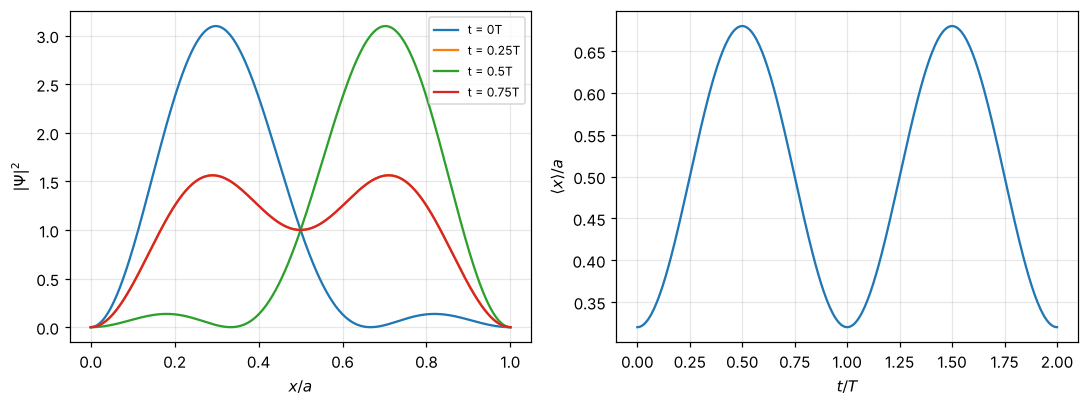

In [2]:
#| label: fig-well-sloshing
#| caption: "An equal superposition of the two lowest infinite-well states, Ψ = (ψ₁e^(−iE₁t/ħ) + ψ₂e^(−iE₂t/ħ))/√2. The density |Ψ|² sloshes back and forth (left, at four times through one period), and ⟨x⟩ oscillates at the angular frequency (E₂ − E₁)/ħ (right). No single stationary state moves."
a = 1.0
X = np.linspace(0, a, 400)
psi = lambda n: np.sqrt(2 / a) * np.sin(n * np.pi * X / a)
E = lambda n: n**2            # units of E1
Tper = 2 * np.pi / (E(2) - E(1))
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.8))
for frac, col in zip([0, 0.25, 0.5, 0.75], ["tab:blue", "tab:orange", "tab:green", "tab:red"]):
    t = frac * Tper
    P = abs((psi(1) * np.exp(-1j * E(1) * t) + psi(2) * np.exp(-1j * E(2) * t)) / np.sqrt(2))**2
    a1.plot(X, P, color=col, label=f"t = {frac}T")
a1.set_xlabel("$x/a$"); a1.set_ylabel("$|\\Psi|^2$"); a1.legend(fontsize=8)
tt = np.linspace(0, 2 * Tper, 300)
xm = 0.5 - (16 / (9 * np.pi**2)) * np.cos((E(2) - E(1)) * tt)
a2.plot(tt / Tper, xm); a2.set_xlabel("$t/T$"); a2.set_ylabel("$\\langle x\\rangle/a$")
plt.tight_layout(); plt.show()

## The Free Particle

With $V = 0$ everywhere, $\psi_k = e^{ikx}$ for every real $k$, with $E = \hbar^2k^2/2m$. These are not normalizable, so they are not physical states by themselves; they are the continuous basis for building packets, $\Psi(x, t) = \frac{1}{\sqrt{2\pi}}\int\phi(k)e^{i(kx - \hbar k^2t/2m)}dk$, which move at the group velocity $\hbar k/m$ and spread (Q-M1 shows both). For scattering problems we use the plane waves anyway and compute *ratios* (reflected and transmitted currents over incident), which do not need normalization.

## The Delta-Function Potential

$V(x) = -\alpha\delta(x)$ with $\alpha > 0$: an infinitely narrow, infinitely deep well.

**Bound state ($E < 0$).** Away from the origin $\psi'' = \kappa^2\psi$ with $\kappa = \sqrt{-2mE}/\hbar$, so $\psi = Be^{-\kappa|x|}$. The derivative jumps by $-2\kappa B$; the jump condition requires that to equal $-2m\alpha B/\hbar^2$:

$$
\kappa = \frac{m\alpha}{\hbar^2},\qquad E = -\frac{m\alpha^2}{2\hbar^2} .
$$ (eq-delta-bound)

Exactly one bound state, however weak the well.

**Scattering ($E > 0$).** Send a wave in from the left: $\psi = Ae^{ikx} + Be^{-ikx}$ for $x < 0$ and $Fe^{ikx}$ for $x > 0$. Matching gives the transmission coefficient $T = |F|^2/|A|^2$:

In [3]:
A, k, m, al, hb = sp.symbols("A k m alpha hbar", positive=True)
B, F = sp.symbols("B F")          # complex amplitudes
beta = m * al / (hb**2 * k)
# continuity at 0, and the derivative jump: psi'(0+) - psi'(0-) = -(2 m alpha / hbar^2) psi(0)
sol = sp.solve([sp.Eq(A + B, F), sp.Eq(sp.I * k * F - sp.I * k * (A - B), -2 * m * al / hb**2 * F)], [B, F], dict=True)[0]
T = sp.simplify(sol[F] * sp.conjugate(sol[F]) / A**2)
R = sp.simplify(sol[B] * sp.conjugate(sol[B]) / A**2)
display(Math(r"T = " + sp.latex(T) + r",\qquad R + T = " + sp.latex(sp.simplify(R + T))))

<IPython.core.display.Math object>

With $E = \hbar^2k^2/2m$ this is $T = 1/\left(1 + m\alpha^2/2\hbar^2E\right)$. The same formula holds for a delta-function *barrier* ($+\alpha$), because only $\alpha^2$ appears: a particle can pass through an infinitely high, infinitely thin wall, and is more likely to the higher its energy.

## The Finite Square Well

$V = -V_0$ for $|x| < a$, zero outside. Bound states ($-V_0 < E < 0$) oscillate inside (wavenumber $l = \sqrt{2m(E + V_0)}/\hbar$) and decay outside ($\kappa = \sqrt{-2mE}/\hbar$). For even states, matching $\psi'/\psi$ at $x = a$ gives $\kappa = l\tan(la)$. In the variables $z = la$ and $z_0 = a\sqrt{2mV_0}/\hbar$ (which measures the well's strength),

$$
\tan z = \sqrt{\left(\frac{z_0}{z}\right)^2 - 1}\quad\text{(even)},\qquad -\cot z = \sqrt{\left(\frac{z_0}{z}\right)^2 - 1}\quad\text{(odd)} .
$$ (eq-finite-well)

These are transcendental: solve them graphically or numerically. There is always at least one (even) bound state, and roughly $2z_0/\pi$ in total.

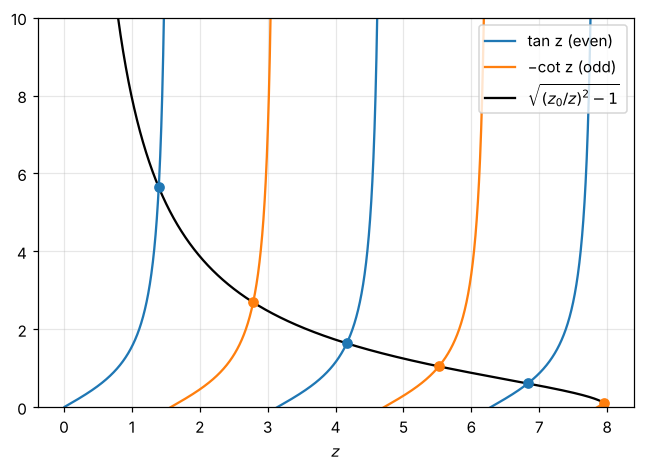

<IPython.core.display.Math object>

In [4]:
#| label: fig-finite-well-graphical
#| caption: "Graphical solution of the finite-well conditions for z₀ = 8. The bound states are where tan z (blue, even) or −cot z (orange, odd) crosses √((z₀/z)² − 1) (black); there are six. As z₀ → ∞ the crossings approach z = nπ/2, the infinite-well values."
z0 = 8.0
z = np.linspace(0.01, z0, 4000)
rhs = np.sqrt((z0 / z)**2 - 1)
fig, ax = plt.subplots()
tz = np.tan(z); tz[np.abs(tz) > 12] = np.nan
cz = -1 / np.tan(z); cz[np.abs(cz) > 12] = np.nan
ax.plot(z, tz, color="tab:blue", label="tan z (even)"); ax.plot(z, cz, color="tab:orange", label="−cot z (odd)")
ax.plot(z, rhs, "k", label="$\\sqrt{(z_0/z)^2 - 1}$")
roots = []
for f, col in [(lambda z: np.tan(z) - np.sqrt((z0 / z)**2 - 1), "tab:blue"), (lambda z: -1 / np.tan(z) - np.sqrt((z0 / z)**2 - 1), "tab:orange")]:
    for n in range(6):
        lo, hi = n * np.pi / 2 + 1e-6, (n + 1) * np.pi / 2 - 1e-6
        hi = min(hi, z0 - 1e-9)
        if lo < hi and np.sign(f(lo)) != np.sign(f(hi)) and np.isfinite(f(lo)) and np.isfinite(f(hi)):
            r = brentq(f, lo, hi)
            if abs(f(r)) < 1e-6: roots.append(r); ax.plot(r, np.sqrt((z0 / r)**2 - 1), "o", color=col)
ax.set_ylim(0, 10); ax.set_xlabel("$z$"); ax.legend(loc="upper right"); plt.show()
display(Math(r"z_n = " + r",\ ".join(f"{r:.3f}" for r in sorted(roots)) + rf",\qquad E_n + V_0 = \frac{{\hbar^2z_n^2}}{{2ma^2}}"))

## Barriers and Tunneling

A rectangular barrier of height $V_0$ and width $a$, with $E < V_0$: inside, $\psi$ is a combination of $e^{\pm\kappa x}$, and matching at both edges gives

$$
T^{-1} = 1 + \frac{V_0^2}{4E(V_0 - E)}\sinh^2(\kappa a),\qquad\kappa = \frac{\sqrt{2m(V_0 - E)}}{\hbar} .
$$ (eq-barrier-T)

For a thick barrier ($\kappa a\gg1$), $\sinh^2\approx e^{2\kappa a}/4$ and $T\approx\frac{16E(V_0 - E)}{V_0^2}e^{-2\kappa a}$: exponentially small, the WKB result of Q-M5 with a prefactor. Above the barrier ($E > V_0$), $\sinh\to\sin$ and $T$ reaches 1 whenever the barrier holds a whole number of half-wavelengths: **transmission resonances**.

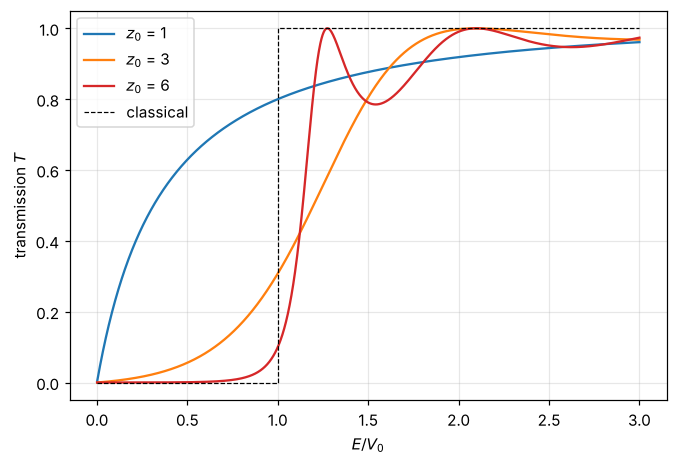

In [5]:
#| label: fig-barrier-transmission
#| caption: "Transmission through a rectangular barrier versus E/V₀, for barrier strengths z₀ = a√(2mV₀)/ħ = 1, 3 and 6. Below the top (E < V₀), T is exponentially small for thick barriers but not zero. Above it, T oscillates and reaches 1 at resonances; classically T would be 0 below and 1 above (dashed)."
def T_barrier(e, z0):        # e = E/V0, z0 = a sqrt(2 m V0)/hbar
    e = np.asarray(e, dtype=complex)
    q = z0 * np.sqrt(1 - e)                         # kappa*a (imaginary above the barrier)
    return np.real(1 / (1 + np.sinh(q)**2 / (4 * e * (1 - e))))
e = np.linspace(0.001, 3, 1500); e = e[np.abs(e - 1) > 1e-4]
fig, ax = plt.subplots()
for z0_, col in [(1, "tab:blue"), (3, "tab:orange"), (6, "tab:red")]:
    ax.plot(e, T_barrier(e, z0_), color=col, label=f"$z_0$ = {z0_}")
ax.plot([0, 1, 1, 3], [0, 0, 1, 1], "k--", lw=0.8, label="classical")
ax.set_xlabel("$E/V_0$"); ax.set_ylabel("transmission $T$"); ax.legend(); plt.show()

::::{prf:example} Level 2 rung: an electron tunneling through an oxide layer
:label: ex-oxide-tunneling

An electron with 1.0 eV meets a 3.0 eV barrier 1.0 nm thick. Estimate $T$, and the effect of thinning the barrier to 0.5 nm.

:::{dropdown} Solution
$\kappa = \sqrt{2m(2.0\text{ eV})}/\hbar = 7.24\times10^9$ m⁻¹, so $\kappa a = 7.24$ and $e^{-2\kappa a} = 5.1\times10^{-7}$. With the prefactor $16(1)(2)/9 = 3.6$, $T\approx1.8\times10^{-6}$. At 0.5 nm, $T\approx3.6e^{-7.24} = 2.6\times10^{-3}$, about 1400 times larger. Halving the thickness multiplies the current by over a thousand: this sensitivity is what makes the scanning tunneling microscope work and what sets a floor on transistor gate oxides.
:::
::::

In [6]:
hbar_, me_, eV_ = 1.054572e-34, 9.10938e-31, 1.602177e-19
kap = np.sqrt(2 * me_ * 2.0 * eV_) / hbar_
for a_ in [1.0e-9, 0.5e-9]:
    exact = T_barrier(1 / 3, kap * a_ / np.sqrt(1 - 1 / 3))
    approx = 16 * 1 * 2 / 9 * np.exp(-2 * kap * a_)
    display(Math(rf"a = {a_ * 1e9:.1f}\ \text{{nm}}:\quad T_{{\rm exact}} = " + sp.latex(sp.Float(exact, 3)) + r",\quad T_{\rm thick} = " + sp.latex(sp.Float(approx, 3))))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

## Looking Ahead to Level 3

The general solution {eq}`eq-general-solution` can be rewritten as $\Psi(x, t) = \int K(x, t; x', 0)\,\Psi(x', 0)\,dx'$, where $K$, the **propagator**, is the amplitude to go from $x'$ to $x$ in time $t$. For a free particle, $K = \sqrt{m/2\pi i\hbar t}\,e^{im(x - x')^2/2\hbar t}$. Sakurai builds it as a sum over stationary states, and Feynman's path integral as a sum over all paths, each weighted by $e^{iS/\hbar}$ with $S$ the classical action of mechanics M5.

## Exercises

### Exercises

1. A particle in the infinite well starts in $\Psi(x, 0) = Ax(a - x)$ (quantum topic 1). Find $c_n$ and show that $|c_1|^2 = 960/\pi^6\approx0.9986$.
2. Show that $\langle x\rangle$ for the equal superposition of $\psi_1$ and $\psi_2$ oscillates with amplitude $16a/9\pi^2$.
3. For the delta well, what fraction of the bound state's probability lies outside $|x| < 1/\kappa$?
4. How many bound states does a finite well with $z_0 = 2$ have? Find the ground state's $z$ numerically.
5. Show that at a transmission resonance $\kappa a = in\pi$ (above the barrier), the wavelength inside fits the barrier a whole number of half-times.

:::{dropdown} Hints
1. $c_n = \sqrt{2/a}\int_0^a\sin(n\pi x/a)\,Ax(a - x)\,dx$; only odd $n$ survive.
2. $\langle x\rangle$ has a cross term $\propto\cos[(E_2 - E_1)t/\hbar]\int x\psi_1\psi_2\,dx$.
3. $\int_{1/\kappa}^\infty\kappa e^{-2\kappa x}dx$, doubled.
4. Count crossings: $2z_0/\pi = 1.27$.
5. $\sinh(i\theta) = i\sin\theta$, so $T = 1$ when $\sin(qa) = 0$ with $q$ the inside wavenumber.
:::

:::{dropdown} Answers
1. $c_n = 8\sqrt{15}/(n\pi)^3$ for odd $n$, 0 for even; $|c_1|^2 = 960/\pi^6 = 0.99856$.
2. $\int_0^ax\psi_1\psi_2dx = -16a/9\pi^2$, so $\langle x\rangle = a/2 - (16a/9\pi^2)\cos(3\pi^2\hbar t/2ma^2)$.
3. $e^{-2} = 0.135$.
4. Two (one even, one odd); the even state has $z = 1.030$.
5. $qa = n\pi$ means $a = n\lambda/2$: a whole number of half-wavelengths, so reflections from the two edges cancel.
:::

## Summary

- Stationary states $\psi(x)e^{-iEt/\hbar}$ solve the TISE; general states are superpositions, and expectation values move through the cross terms.
- Infinite well: $E_n = n^2\pi^2\hbar^2/2ma^2$, sine eigenfunctions, Fourier-series expansions.
- Delta well: one bound state, $E = -m\alpha^2/2\hbar^2$; scattering $T = 1/(1 + m\alpha^2/2\hbar^2E)$.
- Finite well: transcendental conditions, at least one bound state, about $2z_0/\pi$ total.
- Barriers: $T\sim e^{-2\kappa a}$ below the top, resonances above. Tunneling is exponentially sensitive to width.

## Appendix: MyST patterns

Same conventions as the rest of the book: `prf:` directives for definitions, theorems and examples; `:::{dropdown}` for solutions, hints and answers; `$$ ... $$ (label)` with `` {eq}`label` `` for equations; and code cells tagged `hide-input` that start with `#| label:` and `#| caption:` lines.